# Feature analysis: what drives price

Which columns explain `price_usd`, and how strongly. All price relations use **log price** (prices span $15k–$15M,
models train on log price).

1. Correlation heatmap (numeric + binary features)
2. Correlation with log price, ranked
3. Correlation with log price **within each property type**
4. Single-feature variance explained (numeric and categorical on one scale)
5. Location: median $/m² by district × type
6. Model-based importance (gradient boosting + permutation importance)
7. Redundant features

`DATA` defaults to the filtered file (outliers and duplicates removed, see `filter_data.ipynb`); switch it to
`data/clean/data.csv` to see the raw picture.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap

LAB = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "engines" / "common.py").exists())
sys.path.insert(0, str(LAB))
from engines.common import load_config, load_splits

DATA = "data/clean/data_filtered.csv"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
BLUE, RED, GRAY, INK, INK2 = "#257de0", "#ec4647", "#d9d9d9", "#191919", "#666666"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": "#eeeeee", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
})
# diverging: blue (negative) - neutral gray - red (positive); sequential: one blue ramp light -> dark
DIVERGING = LinearSegmentedColormap.from_list("div", ["#1757ac", "#6aabf1", "#efefef", "#f18a8a", "#c42f30"])
SEQUENTIAL = LinearSegmentedColormap.from_list("seq", ["#eef5fe", "#9dc8f7", "#338ced", "#1b64be", "#0e3d7e"])

cfg = load_config()
FC = cfg["features"]
TARGET = cfg["data"]["target"]
CAT, NUM, BIN = FC["categorical"], FC["numeric"], FC["binary"]

d = pd.read_csv(LAB / DATA, encoding="utf-8-sig", low_memory=False)
d["log_price"] = np.log(d[TARGET])
print(f"{DATA}: {len(d):,} rows | {len(CAT)} categorical, {len(NUM)} numeric, {len(BIN)} binary features")


def heatmap(ax, m, cmap, vmin, vmax, fmt="{:.2f}", nan_label=""):
    """Annotated heatmap; text ink flips to white on dark cells."""
    im = ax.imshow(m.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(m.shape[1]), m.columns, rotation=45, ha="right")
    ax.set_yticks(range(m.shape[0]), m.index)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    span = max(abs(vmin), abs(vmax))
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.values[i, j]
            if np.isnan(v):
                ax.text(j, i, nan_label, ha="center", va="center", fontsize=7, color=INK2)
                continue
            dark = (abs(v) / span > 0.6) if vmin < 0 else ((v - vmin) / (vmax - vmin) > 0.6)
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=7, color="white" if dark else INK)
    return im

data/clean/data_filtered.csv: 10,497 rows | 6 categorical, 6 numeric, 12 binary features


## 1. Correlation heatmap

Spearman (rank) correlation: robust to skew and to the long tails in area. Imputation flags are included because
"value was missing" can itself carry price signal.

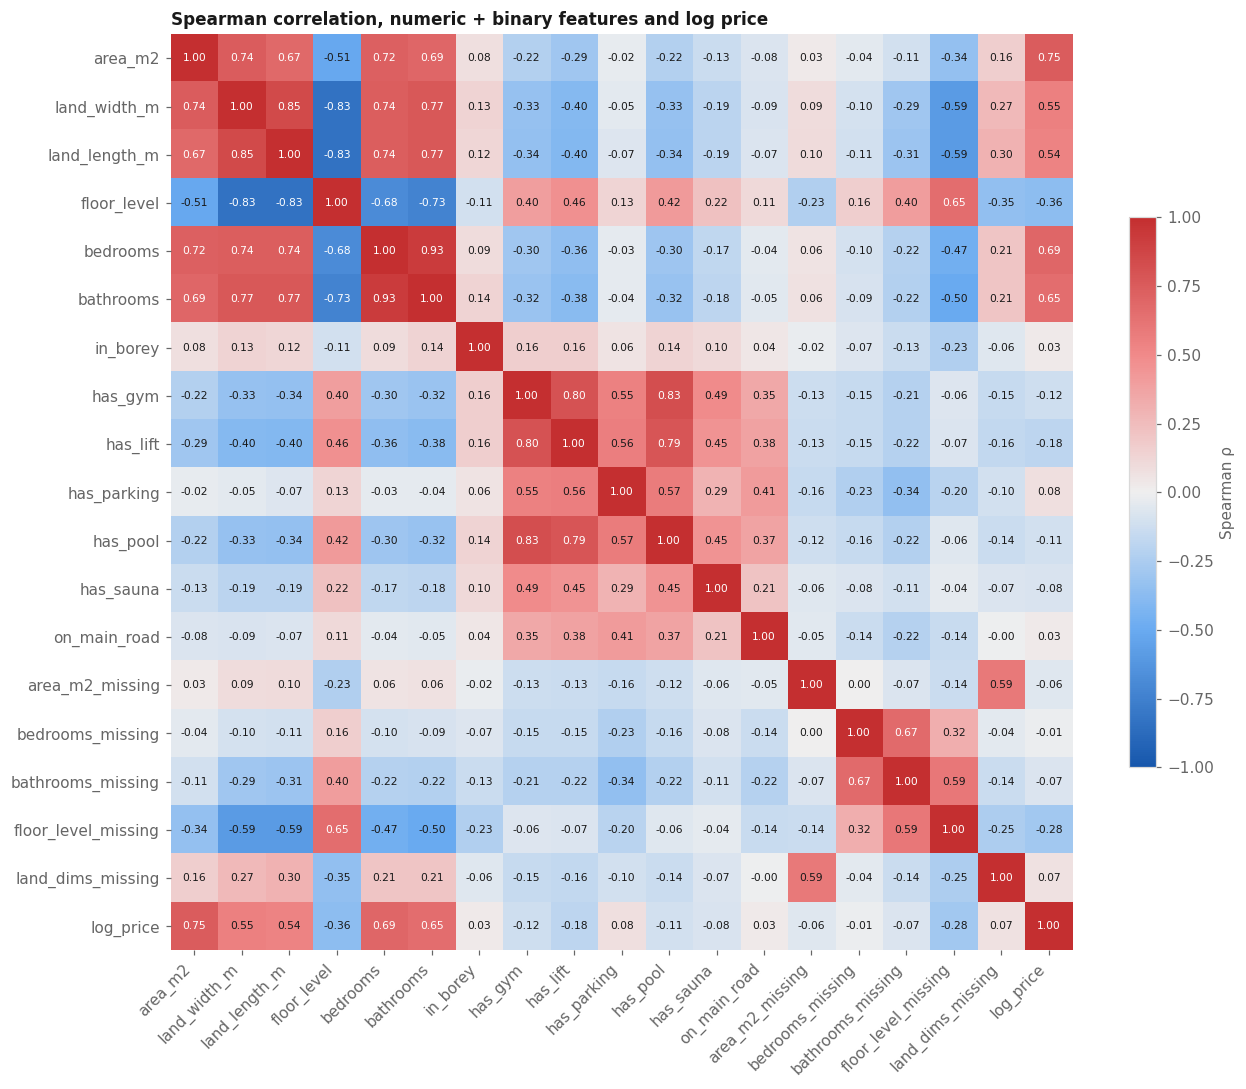

In [2]:
cols = NUM + BIN + ["log_price"]
corr = d[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
im = heatmap(ax, corr, DIVERGING, -1, 1)
fig.colorbar(im, ax=ax, shrink=0.6, label="Spearman ρ")
ax.set_title("Spearman correlation, numeric + binary features and log price")
plt.tight_layout(); plt.show()

## 2. Correlation with log price, ranked

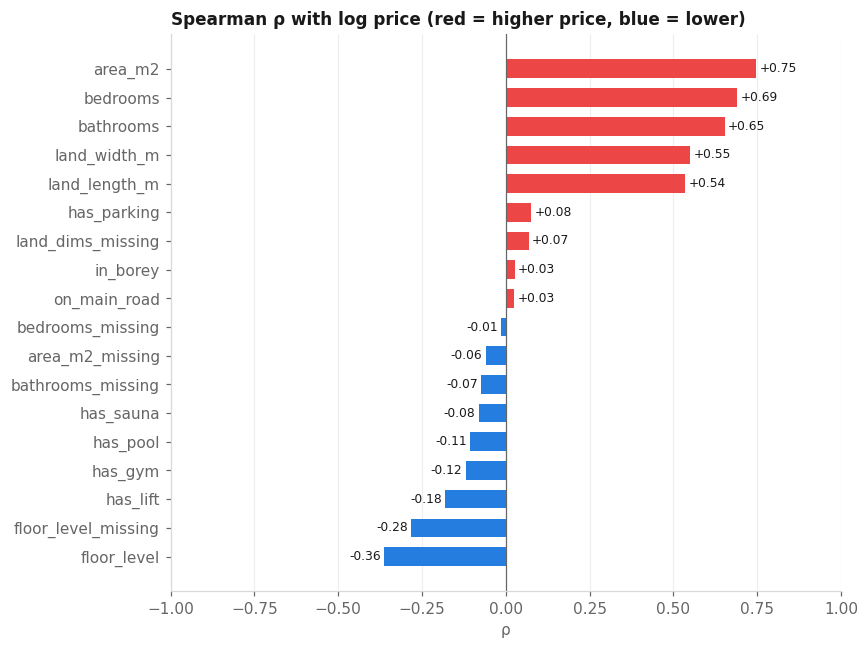

In [3]:
r = corr["log_price"].drop("log_price").sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(r.index, r.values, color=[RED if v > 0 else BLUE for v in r.values], height=0.65)
for y, v in enumerate(r.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), y, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right",
            fontsize=8, color=INK)
ax.axvline(0, color=INK2, lw=0.8)
ax.set_xlim(-1, 1); ax.grid(axis="y", visible=False)
ax.set(title="Spearman ρ with log price (red = higher price, blue = lower)", xlabel="ρ")
plt.tight_layout(); plt.show()

Pooled correlations mix property types: condos are small, cheap and have lifts/gyms; villas are big, expensive and
have no lift. So `has_lift` or `floor_level` can look negative overall for reasons that are just "this is a condo".
Section 3 separates that.

## 3. Correlation with log price within each property type

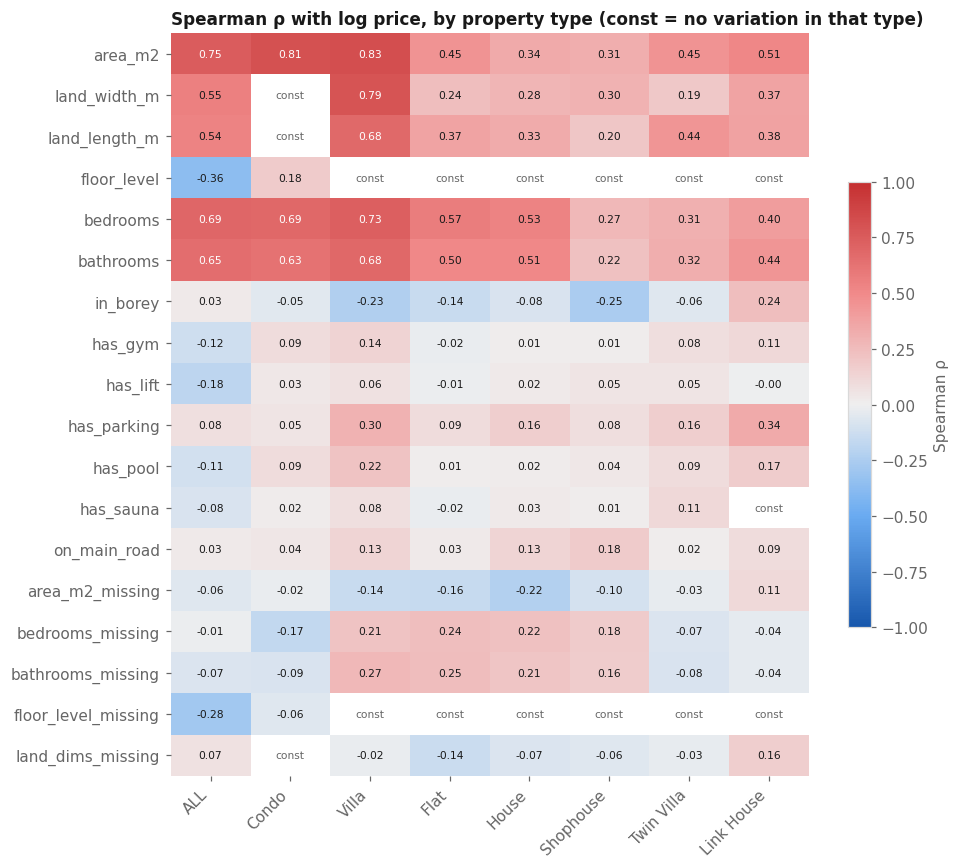

rows per type: {'Condo': 3896, 'Villa': 2104, 'Flat': 1399, 'House': 1275, 'Shophouse': 1090, 'Twin Villa': 408, 'Link House': 325}


In [4]:
types = d["property_type"].value_counts().index.tolist()
within = pd.DataFrame({
    t: d.loc[d.property_type == t, NUM + BIN].apply(
        lambda s: s.corr(d.loc[s.index, "log_price"], method="spearman") if s.nunique() > 1 else np.nan)
    for t in types})
within.insert(0, "ALL", r.reindex(within.index))
fig, ax = plt.subplots(figsize=(9, 8))
im = heatmap(ax, within, DIVERGING, -1, 1, nan_label="const")
fig.colorbar(im, ax=ax, shrink=0.6, label="Spearman ρ")
ax.set_title("Spearman ρ with log price, by property type (const = no variation in that type)")
plt.tight_layout(); plt.show()
print("rows per type:", d["property_type"].value_counts().to_dict())

## 4. Single-feature variance explained

One number per feature on the same scale: share of log-price variance explained by that feature alone (η²).
Categoricals: group means. Numerics: means over 20 quantile bins (catches non-linear effects). Binary: two groups.
Categories with < `min_count` rows are pooled into "other", like the models do, so rare districts don't inflate η².

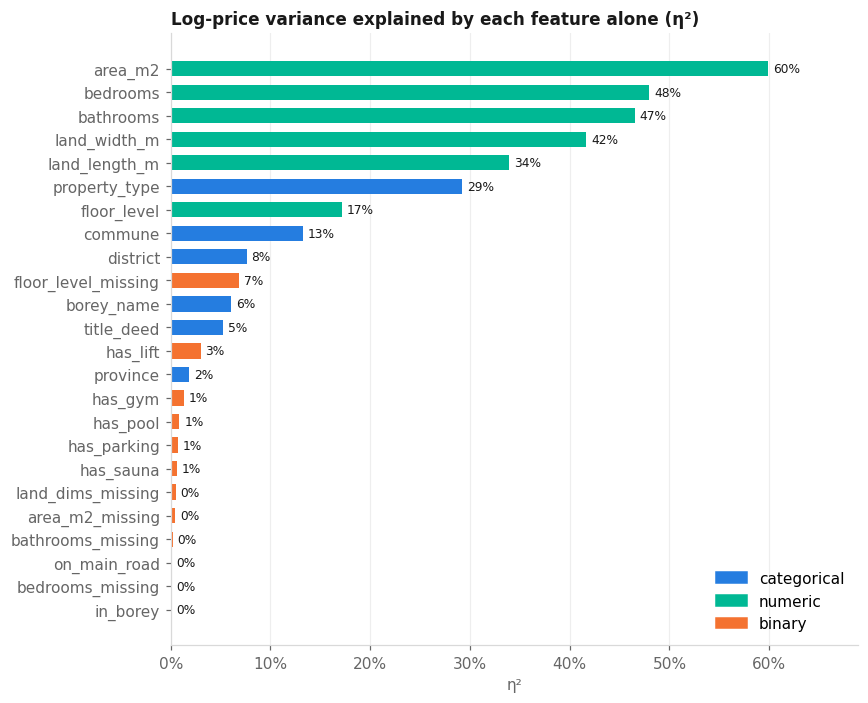

,feature,kind,eta2,levels
0,area_m2,numeric,59.9%,1282
1,bedrooms,numeric,48.0%,21
2,bathrooms,numeric,46.5%,20
3,land_width_m,numeric,41.6%,299
4,land_length_m,numeric,33.9%,344
5,property_type,categorical,29.2%,7
6,floor_level,numeric,17.1%,55
7,commune,categorical,13.2%,132
8,district,categorical,7.6%,33
9,floor_level_missing,binary,6.9%,2


In [5]:
def eta2(groups, y):
    gm = y.groupby(groups).transform("mean")
    return float(((gm - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum())

y = d["log_price"]
rows = []
for c in CAT:
    vc = d[c].value_counts()
    g = d[c].where(d[c].map(vc) >= FC["min_count"], "other")
    rows.append((c, "categorical", eta2(g, y), g.nunique()))
for c in NUM:
    g = pd.qcut(d[c].rank(method="first"), 20, labels=False)
    rows.append((c, "numeric", eta2(g, y), d[c].nunique()))
for c in BIN:
    rows.append((c, "binary", eta2(d[c], y), 2))
ev = pd.DataFrame(rows, columns=["feature", "kind", "eta2", "levels"]).sort_values("eta2")

kind_color = {"categorical": BLUE, "numeric": "#00b894", "binary": "#f47230"}
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(ev.feature, ev.eta2, color=ev.kind.map(kind_color), height=0.65)
for yy, (v, k) in enumerate(zip(ev.eta2, ev.levels)):
    ax.text(v + 0.005, yy, f"{v:.0%}", va="center", fontsize=8, color=INK)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xlim(0, max(ev.eta2) * 1.15)
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=col, label=k) for k, col in kind_color.items()], frameon=False, loc="lower right")
ax.set(title="Log-price variance explained by each feature alone (η²)", xlabel="η²")
plt.tight_layout(); plt.show()
ev.sort_values("eta2", ascending=False).reset_index(drop=True).style.format({"eta2": "{:.1%}"})

## 5. Location: median price per m² by district × type

Top 20 districts by listing count. Blank cell = fewer than 5 listings of that type there. $/m² compares within a
type only: condos use unit floor area, the others use land area.

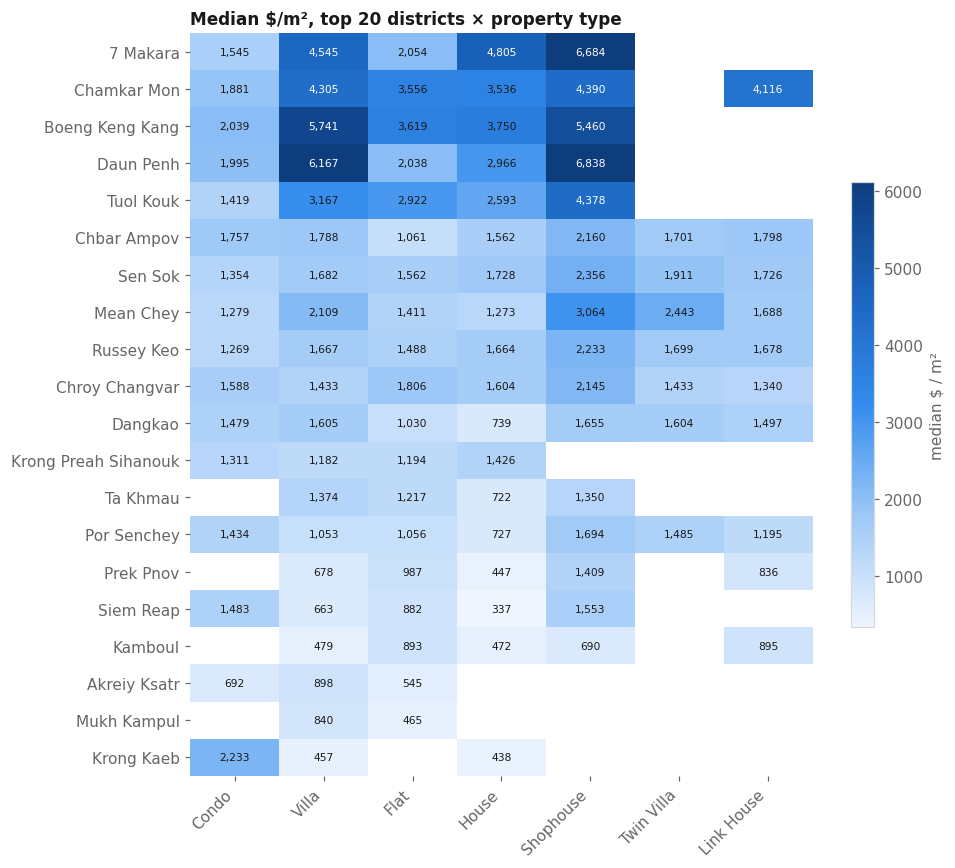

In [6]:
d["ppm2"] = d[TARGET] / d["area_m2"]
top = d["district"].value_counts().head(20).index
sub = d[d.district.isin(top)]
pv = sub.pivot_table(index="district", columns="property_type", values="ppm2", aggfunc="median")
n = sub.pivot_table(index="district", columns="property_type", values="ppm2", aggfunc="size")
pv = pv.where(n >= 5)[types].loc[pv.median(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(9, 8))
im = heatmap(ax, pv, SEQUENTIAL, np.nanmin(pv.values), np.nanpercentile(pv.values, 98), fmt="{:,.0f}")
fig.colorbar(im, ax=ax, shrink=0.6, label="median $ / m²")
ax.set_title("Median $/m², top 20 districts × property type")
plt.tight_layout(); plt.show()

## 6. Model-based importance

Gradient boosting on log price with all model features (categoricals native), trained on the seed-42 train split
and scored on its test split. **Permutation importance** = how much test RMSE (log) gets worse when one feature's
values are shuffled. Unlike correlation it counts interactions (e.g. area × type) and ignores redundant copies.

test RMSE log 0.428 | MdAPE 22.4%


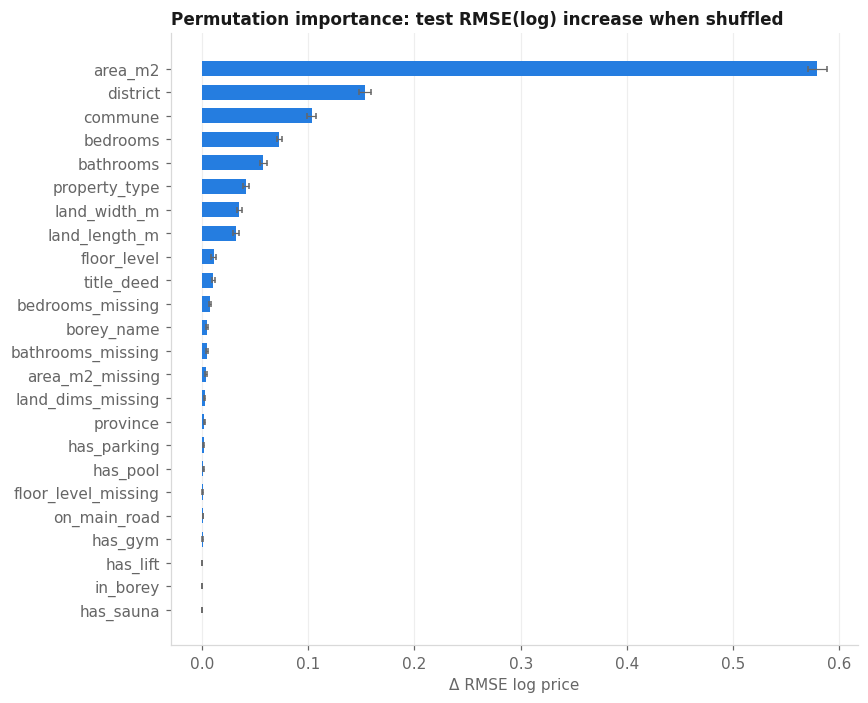

In [7]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

dc = cfg["data"]
train, val, test = load_splits(DATA, dc["test_size"], dc["val_size"], dc["seed"])
train = pd.concat([train, val], ignore_index=True)
FEATS = CAT + NUM + BIN


def encode(df, cats):
    x = df[FEATS].copy()
    for c in CAT:
        x[c] = pd.Categorical(x[c].astype(str), categories=cats[c]).codes.astype(float)
        x.loc[x[c] < 0, c] = np.nan
    return x

cats = {c: sorted(train[c].astype(str).unique()) for c in CAT}
Xtr, Xte = encode(train, cats), encode(test, cats)
ytr, yte = np.log(train[TARGET]), np.log(test[TARGET])
gb = HistGradientBoostingRegressor(categorical_features=[FEATS.index(c) for c in CAT], max_iter=500,
                                   learning_rate=0.05, random_state=0).fit(Xtr, ytr)
pred = gb.predict(Xte)
print(f"test RMSE log {np.sqrt(np.mean((pred - yte) ** 2)):.3f} | "
      f"MdAPE {np.median(np.abs(np.exp(pred) - test[TARGET]) / test[TARGET]) * 100:.1f}%")

pi = permutation_importance(gb, Xte, yte, scoring="neg_root_mean_squared_error", n_repeats=10, random_state=0)
imp = pd.DataFrame({"feature": FEATS, "mean": pi.importances_mean, "std": pi.importances_std}).sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(imp.feature, imp["mean"], xerr=imp["std"], color=BLUE, height=0.65,
        error_kw=dict(ecolor=INK2, lw=0.8, capsize=2))
ax.grid(axis="y", visible=False)
ax.set(title="Permutation importance: test RMSE(log) increase when shuffled", xlabel="Δ RMSE log price")
plt.tight_layout(); plt.show()

## 7. Redundant features

In [8]:
pairs = (corr.drop(index="log_price", columns="log_price").where(np.triu(np.ones(corr.shape[0] - 1, bool), 1))
         .stack().rename("rho").reset_index())
pairs = pairs.reindex(pairs.rho.abs().sort_values(ascending=False).index).head(12)
pairs.columns = ["feature A", "feature B", "Spearman ρ"]
pairs.style.format({"Spearman ρ": "{:+.2f}"}).hide(axis="index")

feature A,feature B,Spearman ρ
bedrooms,bathrooms,+0.93
land_width_m,land_length_m,+0.85
land_width_m,floor_level,-0.83
land_length_m,floor_level,-0.83
has_gym,has_pool,+0.83
has_gym,has_lift,+0.80
has_lift,has_pool,+0.79
land_width_m,bathrooms,+0.77
land_length_m,bathrooms,+0.77
area_m2,land_width_m,+0.74


## Summary

- **Size dominates.** `area_m2` alone explains ~60% of log-price variance and is by far the top permutation
  importance. `bedrooms` / `bathrooms` / land width & length add little on top: they are mostly other measures of size
  (see section 7).
- **Location is second.** `district` and `commune` rank right after area in the model, although alone they explain
  only ~8–13%: location matters *given* size and type (price per m² in 7 Makara / BKK / Daun Penh is 3–5× the
  outer districts).
- **Property type** explains ~29% alone, but much of that is size again; it matters mainly through interactions
  (area means unit area for condos, land area for the rest).
- **Amenity flags are weak.** `has_gym`, `has_lift`, `has_pool`, `has_sauna`, `on_main_road`, `in_borey` add almost
  nothing. Their negative pooled correlations are a condo effect (section 3), not "a lift lowers price".
- **`floor_level`** only varies for condos, where it is mildly positive (higher floor, higher price).
- **Imputation flags** carry a little signal within types (e.g. `area_m2_missing` lower prices for houses).